# Projet EuroSAT · Sujet 1 : classer les paysages avec les 13 bandes du satellite

**Groupe :** *(vos trois prénoms)*

## Sujet

EuroSAT rassemble 27 000 images du satellite Sentinel-2 de l'Agence spatiale européenne, de 64×64 pixels, réparties en 10 types de paysages. Chaque image comporte **13 bandes spectrales**, dont plusieurs dans l'infrarouge, invisible à l'œil.

**Mission.** Exploiter les 13 bandes pour classer les paysages, et montrer ce que les bandes invisibles apportent.

**Approche.** Un ResNet pré-entraîné sur des images en couleurs (par exemple celui de `torchvision`), dont on **modifie la première couche** pour qu'il accepte 13 canaux au lieu de 3, puis **fine-tuning**. A vous de voir lequel.

**Critère de réussite.** L'accuracy et le F1 de chaque classe sur le jeu de test, et les classes qui profitent le plus des bandes supplémentaires.

**Baseline.** Le même modèle, avec le même protocole, entraîné uniquement sur les 3 bandes rouge, verte et bleue.

## Consignes

- **Tout faire dans ce notebook.**
- **Sans IA** : pas de Copilot, de ChatGPT ni d'autre assistant. Vous en êtes capables ! Si besoin, venez me voir.
- **À 15 h, vous présenterez vos résultats** :
  1. Présenter l'objectif
  2. La stratégie que vous avez choisie
  3. Expliquer les différentes étapes que vous avez dû faire
  4. Expliquer les problèmes rencontrés
  5. Présenter vos résultats
  6. Les analyser et les critiquer
- **Comparez les performances obtenues à une baseline** (voir le sujet ci-dessus).

## Récupérer les données

La cellule ci-dessous télécharge la version **13 bandes** d'EuroSAT (une seule fois), puis charge un sous-échantillon en mémoire :

| Variable | Contenu |
|---|---|
| `X_train`, `X_val`, `X_test` | images, tableaux numpy `uint16` de forme `(N, 13, 64, 64)` : valeurs brutes du satellite, **à normaliser vous-mêmes** |
| `y_train`, `y_val`, `y_test` | classe de chaque image, entier de 0 à 9 |
| `CLASSES` | nom de chaque classe |
| `BANDES`, `RVB` | nom des 13 bandes ; indices des bandes rouge, verte et bleue (`X[:, RVB]` donne l'image en couleurs) |

**Attention : l'archive pèse environ 2 Go.** Si l'enseignant vous fournit le fichier `EuroSATallBands.zip`, copiez-le dans le dossier `data/` avant de lancer la cellule : il ne sera pas re-téléchargé.

Par défaut, la fonction `charger` garde 300 images par classe pour le train, 100 pour la validation et 200 pour le test. Vous pouvez changer ces nombres (`None` = toutes les images).

Vos machines n'ont pas de GPU : mettez votre code au point sur un petit sous-échantillon, mesurez le temps d'une époque, puis seulement passez à plus de données.

In [9]:
%pip install -q numpy matplotlib requests tifffile imagecodecs

# ----- Outil de téléchargement (rien à modifier) -----
import os, hashlib
import requests

def telecharger(url, chemin, md5=None, sha256=None):
    """Télécharge url dans chemin, sauf si le fichier est déjà là."""
    if os.path.exists(chemin):
        print(f"Déjà présent : {chemin}")
        return
    os.makedirs(os.path.dirname(chemin), exist_ok=True)
    print(f"Téléchargement de {os.path.basename(chemin)} :", end=" ")
    empreinte = hashlib.md5() if md5 else hashlib.sha256()
    with requests.get(url, stream=True, timeout=60) as r:
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0))
        recu, palier = 0, 0
        with open(chemin + ".part", "wb") as f:
            for bloc in r.iter_content(chunk_size=1 << 20):
                f.write(bloc)
                empreinte.update(bloc)
                recu += len(bloc)
                while total and recu * 100 // total >= palier:
                    print(f"{palier} %", end=" ")
                    palier += 10
    print()
    attendu = md5 or sha256
    if attendu and empreinte.hexdigest() != attendu:
        os.remove(chemin + ".part")
        raise RuntimeError("Fichier corrompu : relancez la cellule.")
    os.replace(chemin + ".part", chemin)

# ----- Chargement des données -----

import io, zipfile
import numpy as np
import tifffile

DATA_DIR = "data"
CLASSES_EN = ["AnnualCrop", "Forest", "HerbaceousVegetation", "Highway", "Industrial",
              "Pasture", "PermanentCrop", "Residential", "River", "SeaLake"]
CLASSES = ["culture annuelle", "forêt", "végétation herbacée", "autoroute", "zone industrielle",
           "pâturage", "culture permanente", "zone résidentielle", "rivière", "mer ou lac"]
BANDES = ["B01", "B02", "B03", "B04", "B05", "B06", "B07", "B08", "B09", "B10", "B11", "B12", "B8A"]
RVB = [3, 2, 1]   # B04 = rouge, B03 = vert, B02 = bleu

# Images 13 bandes (environ 2 Go)
ARCHIVE = os.path.join(DATA_DIR, "EuroSATallBands.zip")
telecharger("https://huggingface.co/datasets/torchgeo/eurosat/resolve/1ce6f1bfb56db63fd91b6ecc466ea67f2509774c/EuroSATallBands.zip",
            ARCHIVE, sha256="751f070f9bffa2eed48b24ca2dd0b02959280c08837e8c9a5532a67ba611df59")

# Découpage officiel train / validation / test (le même que la bibliothèque torchgeo)
URL_SPLITS = "https://huggingface.co/datasets/torchgeo/eurosat/resolve/1ce6f1bfb56db63fd91b6ecc466ea67f2509774c/"
SPLITS = {}
for split in ["train", "val", "test"]:
    fichier = os.path.join(DATA_DIR, f"eurosat-{split}.txt")
    telecharger(URL_SPLITS + f"eurosat-{split}.txt", fichier)
    with open(fichier) as f:
        SPLITS[split] = [os.path.splitext(os.path.basename(ligne.strip()))[0] for ligne in f if ligne.strip()]

# Les images sont lues directement dans l'archive, sans la décompresser
archive = zipfile.ZipFile(ARCHIVE)
MEMBRES = {os.path.splitext(os.path.basename(m))[0]: m for m in archive.namelist() if m.endswith(".tif")}

def _choisir(split, n_par_classe, graine):
    """Noms des images d'un split, éventuellement limités à n_par_classe images par classe."""
    noms = [n for n in SPLITS[split] if n in MEMBRES]
    if n_par_classe is None:
        return noms
    rng = np.random.default_rng(graine)
    garde = []
    for c in CLASSES_EN:
        noms_c = [n for n in noms if n.rsplit("_", 1)[0] == c]
        rng.shuffle(noms_c)
        garde += noms_c[:n_par_classe]
    return garde

def charger(split, n_par_classe=None, graine=0):
    """Renvoie X (N, 13, 64, 64) en uint16 et y (N,) pour le split 'train', 'val' ou 'test'."""
    noms = _choisir(split, n_par_classe, graine)
    X = np.empty((len(noms), 13, 64, 64), dtype=np.uint16)
    y = np.empty(len(noms), dtype=np.int64)
    for i, nom in enumerate(noms):
        image = tifffile.imread(io.BytesIO(archive.read(MEMBRES[nom])))
        if image.shape[-1] == 13:            # (64, 64, 13) -> (13, 64, 64)
            image = image.transpose(2, 0, 1)
        X[i] = image
        y[i] = CLASSES_EN.index(nom.rsplit("_", 1)[0])
    return X, y

X_train, y_train = charger("train", n_par_classe=300)
X_val,   y_val   = charger("val",   n_par_classe=100)
X_test,  y_test  = charger("test",  n_par_classe=200)


[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Déjà présent : data/EuroSATallBands.zip
Déjà présent : data/eurosat-train.txt
Déjà présent : data/eurosat-val.txt
Déjà présent : data/eurosat-test.txt


Taille complète des splits : {'train': 16200, 'val': 5400, 'test': 5400}
Chargé en mémoire : train (3000, 13, 64, 64) | val (1000, 13, 64, 64) | test (2000, 13, 64, 64)

Classe                  train    val   test
0  culture annuelle       300    100    200
1  forêt                  300    100    200
2  végétation herbacée    300    100    200
3  autoroute              300    100    200
4  zone industrielle      300    100    200
5  pâturage               300    100    200
6  culture permanente     300    100    200
7  zone résidentielle     300    100    200
8  rivière                300    100    200
9  mer ou lac             300    100    200

Valeur moyenne de chaque bande (train) :
{'B01': 1357, 'B02': 1121, 'B03': 1046, 'B04': 946, 'B05': 1206, 'B06': 2032, 'B07': 2410, 'B08': 2337, 'B09': 744, 'B10': 12, 'B11': 1833, 'B12': 1124, 'B8A': 2639}


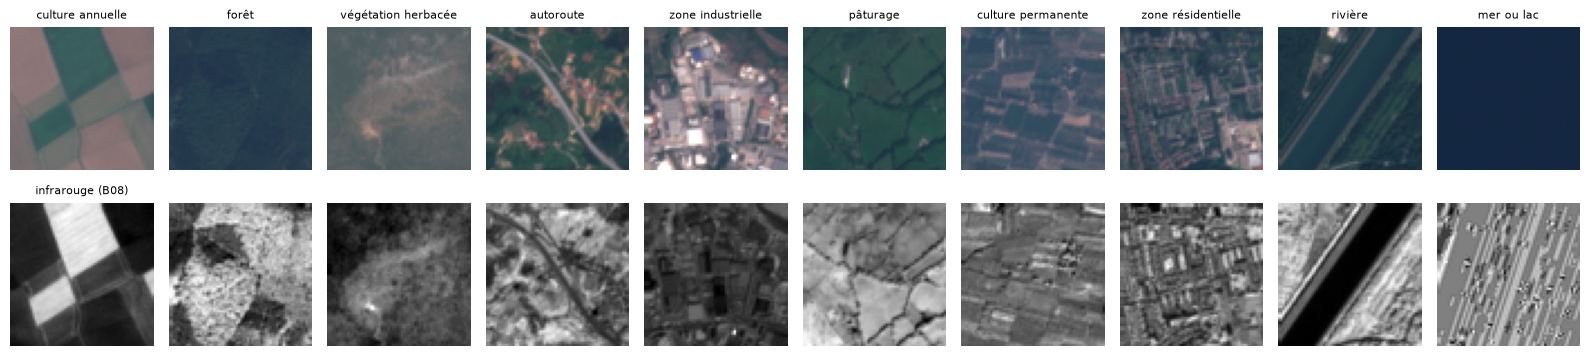

In [10]:
import matplotlib.pyplot as plt

print("Taille complète des splits :", {s: len(v) for s, v in SPLITS.items()})
print("Chargé en mémoire : train", X_train.shape, "| val", X_val.shape, "| test", X_test.shape)
print()
print(f"{'Classe':<22}{'train':>7}{'val':>7}{'test':>7}")
for c, nom in enumerate(CLASSES):
    print(f"{c}  {nom:<19}{(y_train == c).sum():>7}{(y_val == c).sum():>7}{(y_test == c).sum():>7}")
print()
print("Valeur moyenne de chaque bande (train) :")
print({b: int(m) for b, m in zip(BANDES, X_train.mean(axis=(0, 2, 3)))})

# Première ligne : l'image en couleurs. Seconde ligne : la bande B08 (proche infrarouge).
fig, axes = plt.subplots(2, 10, figsize=(16, 3.8))
for c in range(10):
    i = np.flatnonzero(y_train == c)[0]
    rvb = np.clip(X_train[i, RVB].transpose(1, 2, 0) / 3000, 0, 1)
    axes[0, c].imshow(rvb)
    axes[0, c].set_title(CLASSES[c], fontsize=8)
    axes[1, c].imshow(X_train[i, BANDES.index("B08")], cmap="gray")
    for ax in axes[:, c]:
        ax.axis("off")
axes[1, 0].set_title("infrarouge (B08)", fontsize=8)
plt.tight_layout()
plt.show()

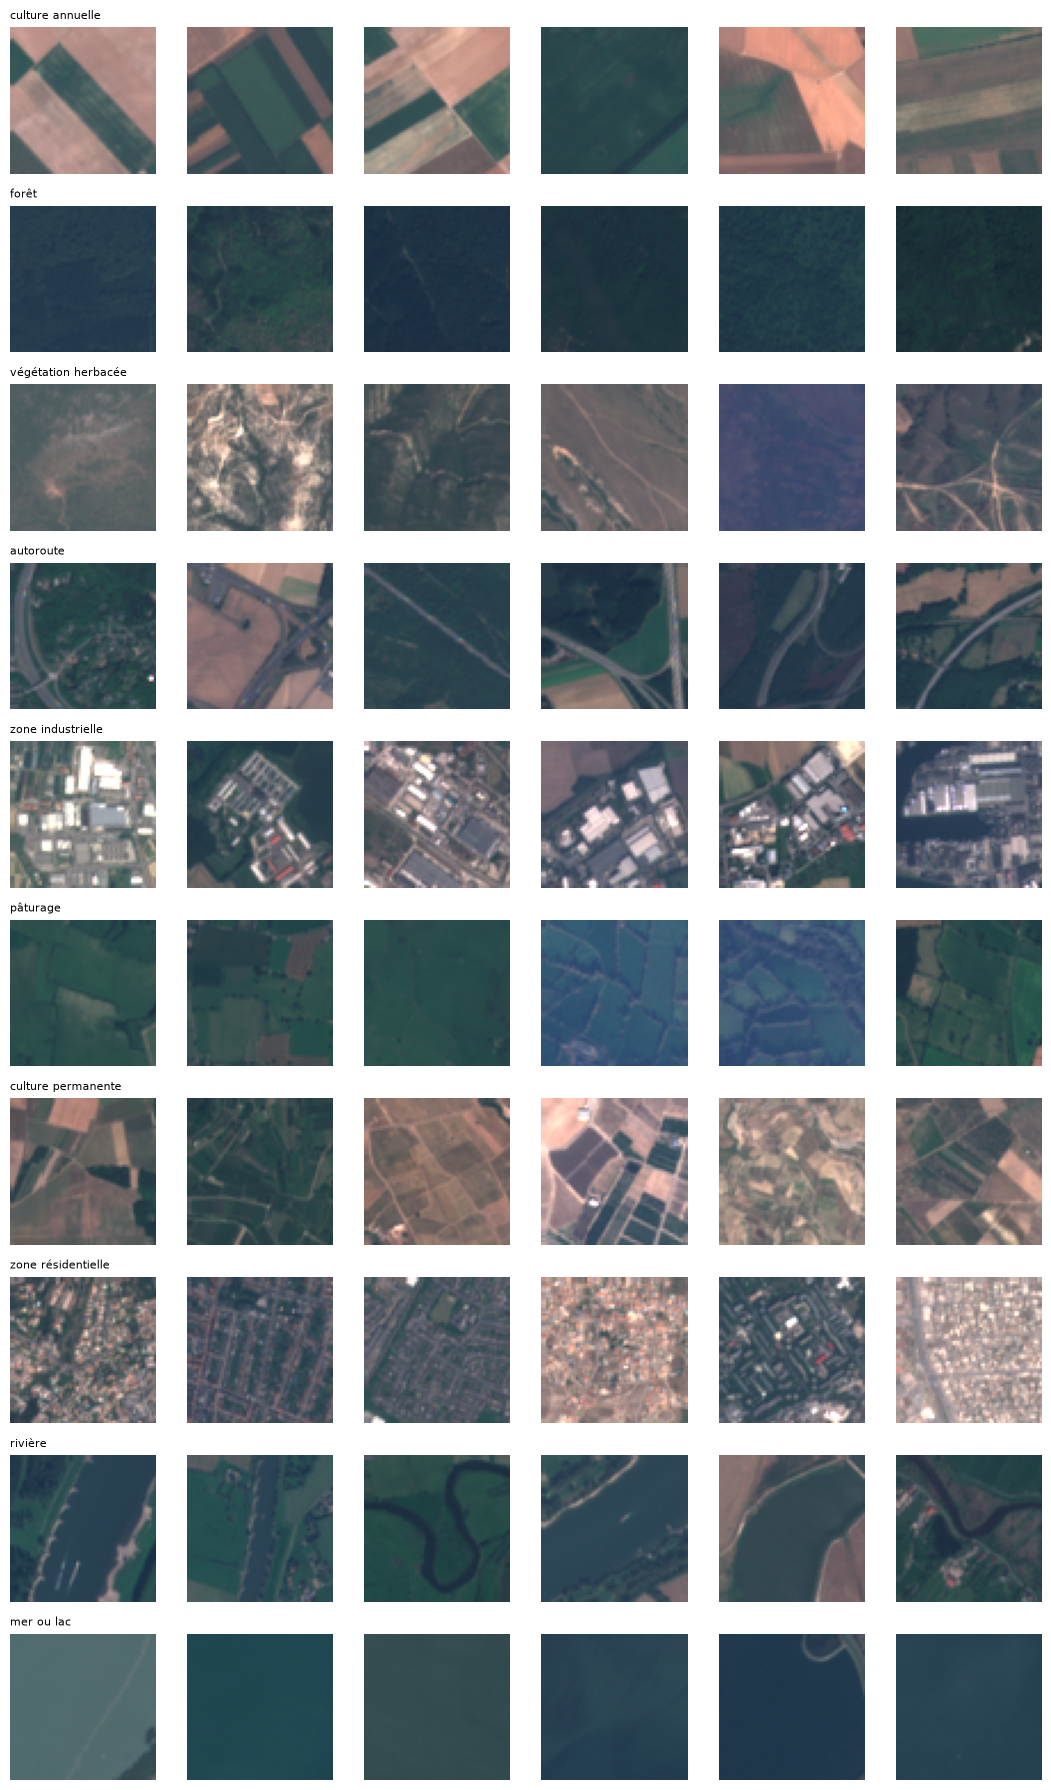

In [11]:
N_PAR_CLASSE = 6
fig, axes = plt.subplots(len(CLASSES), N_PAR_CLASSE, figsize=(1.8 * N_PAR_CLASSE, 1.8 * len(CLASSES)))
rng = np.random.default_rng(0)
for c in range(len(CLASSES)):
    indices = np.flatnonzero(y_train == c)
    choisis = rng.choice(indices, size=min(N_PAR_CLASSE, len(indices)), replace=False)
    for j in range(N_PAR_CLASSE):
        ax = axes[c, j]
        ax.axis("off")
        if j < len(choisis):
            ax.imshow(np.clip(X_train[choisis[j], RVB].transpose(1, 2, 0) / 3000, 0, 1))
    axes[c, 0].set_title(CLASSES[c], fontsize=8, loc="left")
plt.tight_layout()
plt.show()


## Votre travail

### Plan de travail

| Partie | Ce qu'on fait |
|---|---|
| 1 | Normaliser les 13 bandes (statistiques calculées sur le train seulement) |
| 2 | `Dataset` / `DataLoader` + augmentation adaptée aux images satellite |
| 3 | ResNet18 pré-entraîné, dont on remplace `conv1` pour accepter 13 canaux |
| 4 | Boucle d'entraînement commune aux deux modèles (protocole identique) |
| 5 | **Baseline** : le même modèle sur les 3 bandes rouge / vert / bleu |
| 6 | **Modèle complet** : les 13 bandes |
| 7 | Évaluation sur le test : accuracy, F1 par classe, matrices de confusion, gain par classe |
| 8 | Analyse et critique |

La règle du jeu pour que la comparaison soit honnête : **une seule chose change entre la baseline et le modèle complet**, le nombre de bandes en entrée. Même découpage, même graine aléatoire, même optimiseur, même nombre d'époques, même augmentation.

## Partie 1 · Normalisation

Les valeurs sont des `uint16` de réflectance brute, pas des pixels 0-255 : on ne peut donc pas réutiliser la normalisation d'ImageNet. De plus, les bandes n'ont pas du tout la même échelle (B02 vaut quelques milliers, B10 — le cirrus — quelques dizaines). Sans mise à l'échelle, les bandes « fortes » écraseraient les autres dans le gradient.

On standardise donc chaque bande par sa propre moyenne et son propre écart-type, **calculés uniquement sur le train** (les calculer sur tout le dataset serait une fuite d'information du test vers l'entraînement).

In [22]:
import os, time, copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet18, ResNet18_Weights

GRAINE = 0
DEVICE = torch.device("mps" if torch.cuda.is_available() else "cpu")

TOUTES_BANDES = list(range(13))   # les 13 bandes
# RVB (defini plus haut) = [3, 2, 1] : les 3 bandes visibles, pour la baseline

def stats_bandes(X):
    """Moyenne et ecart-type de chaque bande, sur tout le jeu passe en argument."""
    Xf = X.astype(np.float32)
    return Xf.mean(axis=(0, 2, 3)), Xf.std(axis=(0, 2, 3)) + 1e-6

MOYENNES, ECARTS = stats_bandes(X_train)   # <-- train uniquement

print(f"\n{'bande':<7}{'moyenne':>10}{'ecart-type':>13}   role")
roles = {"B01": "aerosols", "B02": "bleu", "B03": "vert", "B04": "rouge",
         "B05": "red edge", "B06": "red edge", "B07": "red edge",
         "B08": "proche infrarouge", "B09": "vapeur d'eau", "B10": "cirrus",
         "B11": "infrarouge court", "B12": "infrarouge court", "B8A": "proche infrarouge"}
for b, m, e in zip(BANDES, MOYENNES, ECARTS):
    etoile = " *" if BANDES.index(b) in RVB else "  "
    print(f"{b:<7}{m:>10.1f}{e:>13.1f} {etoile} {roles[b]}")
print("\n* = bandes utilisees par la baseline")


bande     moyenne   ecart-type   role
B01        1357.3        244.2    aerosols
B02        1121.1        331.4  * bleu
B03        1046.8        389.5  * vert
B04         946.1        587.3  * rouge
B05        1206.3        554.1    red edge
B06        2032.4        852.6    red edge
B07        2410.4       1081.6    red edge
B08        2337.8       1115.4    proche infrarouge
B09         744.9        401.7    vapeur d'eau
B10          12.2          4.7    cirrus
B11        1833.7        976.9    infrarouge court
B12        1124.2        745.6    infrarouge court
B8A        2639.7       1223.1    proche infrarouge

* = bandes utilisees par la baseline


## Partie 2 · `Dataset` et augmentation

Le `Dataset` fait trois choses :

1. **sélectionner les bandes** demandées (`[0..12]` pour le modèle complet, `RVB` pour la baseline) — c'est le seul paramètre qui changera entre les deux expériences ;
2. **standardiser** avec les statistiques du train ;
3. **augmenter** (train uniquement).

Pour l'augmentation on utilise seulement des symétries et des rotations de 90° : une image satellite vue du dessus n'a pas de « haut », donc ces transformations donnent des images parfaitement plausibles. On évite en revanche les décalages de couleur ou de luminosité habituels en vision : ici l'intensité d'une bande *est* l'information physique (la réflectance), la déformer détruirait justement ce qu'on veut mesurer.

In [23]:
class EuroSAT(Dataset):
    """Images EuroSAT normalisees, limitees a une liste de bandes."""

    def __init__(self, X, y, bandes, moyennes=MOYENNES, ecarts=ECARTS, augmente=False):
        self.X, self.y = X, y
        self.bandes = list(bandes)
        self.mo = moyennes[self.bandes].reshape(-1, 1, 1)   # (C, 1, 1)
        self.ec = ecarts[self.bandes].reshape(-1, 1, 1)
        self.augmente = augmente

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        img = self.X[i][self.bandes].astype(np.float32)     # (C, 64, 64)
        img = (img - self.mo) / self.ec                     # standardisation par bande
        if self.augmente:
            if np.random.rand() < 0.5:
                img = img[:, :, ::-1]                       # symetrie gauche-droite
            if np.random.rand() < 0.5:
                img = img[:, ::-1, :]                       # symetrie haut-bas
            k = np.random.randint(4)
            if k:
                img = np.rot90(img, k, axes=(1, 2))         # rotation de k x 90 degres
        return torch.from_numpy(np.ascontiguousarray(img)), int(self.y[i])


JEUX = {"train": (X_train, y_train), "val": (X_val, y_val), "test": (X_test, y_test)}


def charger_loaders(bandes, batch=64, jeux=None, stats=None):
    """Les trois DataLoader pour un choix de bandes donne.

    jeux  : dict {"train": (X, y), "val": ..., "test": ...}, par defaut JEUX
    stats : (moyennes, ecarts) a utiliser, par defaut celles du train complet
    """
    jeux = jeux or JEUX
    mo, ec = stats or (MOYENNES, ECARTS)
    tr = DataLoader(EuroSAT(*jeux["train"], bandes, mo, ec, augmente=True),
                    batch_size=batch, shuffle=True, num_workers=2, drop_last=False)
    va = DataLoader(EuroSAT(*jeux["val"], bandes, mo, ec), batch_size=batch, num_workers=2)
    te = DataLoader(EuroSAT(*jeux["test"], bandes, mo, ec), batch_size=batch, num_workers=2)
    return tr, va, te

# Verification : formes et ordre de grandeur apres normalisation
for nom, bandes in [("13 bandes", TOUTES_BANDES), ("RVB", RVB)]:
    xb, yb = next(iter(DataLoader(EuroSAT(X_train, y_train, bandes), batch_size=8)))
    print(f"{nom:<10} batch {tuple(xb.shape)}  moyenne {xb.mean():+.3f}  ecart-type {xb.std():.3f}")

13 bandes  batch (8, 13, 64, 64)  moyenne +0.753  ecart-type 0.784
RVB        batch (8, 3, 64, 64)  moyenne +0.926  ecart-type 0.828


## Partie 3 · Le modèle : ResNet18 pré-entraîné, première couche remplacée

`conv1` d'un ResNet18 ImageNet a une forme `(64, 3, 7, 7)` : 64 filtres sur 3 canaux. Il faut une couche `(64, 13, 7, 7)`. Trois façons de la remplir :

| Stratégie | Problème |
|---|---|
| Réinitialiser au hasard | on jette les filtres de bords/textures appris sur ImageNet, qui sont précisément la partie la plus réutilisable |
| Copier RVB, zéros ailleurs | les 10 bandes invisibles ne reçoivent aucun gradient utile au départ (sortie nulle) |
| **Copier RVB sur les bandes visibles, et la moyenne des 3 poids RVB sur les 10 autres** | retenu |

On copie donc les poids du rouge sur B04, du vert sur B03, du bleu sur B02, et sur les dix autres canaux la moyenne des trois. Un filtre de contour reste alors un filtre de contour quelle que soit la bande, et le fine-tuning spécialise ensuite chaque canal.

Dernier détail : la somme sur 13 canaux au lieu de 3 multiplierait par ~4 l'amplitude des activations à l'entrée de la première `BatchNorm`. On rééchelonne par `3/13` pour partir dans le même régime numérique que le réseau d'origine.

`fc` passe de 1000 à 10 sorties. Tout le reste est entraîné (fine-tuning complet) : 64×64 et des images satellite sont assez loin d'ImageNet pour qu'un simple entraînement de la tête soit insuffisant.

In [24]:
def construire_modele(bandes, n_classes=10):
    """ResNet18 pre-entraine, conv1 adaptee a len(bandes) canaux, fc a n_classes."""
    bandes = list(bandes)
    n_canaux = len(bandes)
    modele = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)

    poids_rgb = modele.conv1.weight.data.clone()              # (64, 3, 7, 7) : R, V, B
    moyen = poids_rgb.mean(dim=1, keepdim=True)               # (64, 1, 7, 7)
    nouveaux = moyen.repeat(1, n_canaux, 1, 1)                # moyenne partout...
    for src, bande in enumerate(RVB):                         # ...puis R, V, B a leur place
        if bande in bandes:
            nouveaux[:, bandes.index(bande)] = poids_rgb[:, src]
    nouveaux *= 3.0 / n_canaux                                # garder l'amplitude d'origine

    conv = nn.Conv2d(n_canaux, 64, kernel_size=7, stride=2, padding=3, bias=False)
    conv.weight.data = nouveaux
    modele.conv1 = conv
    modele.fc = nn.Linear(modele.fc.in_features, n_classes)
    return modele

m = construire_modele(TOUTES_BANDES)
print("conv1 :", tuple(m.conv1.weight.shape), "| fc :", tuple(m.fc.weight.shape))
print("parametres entrainables :", sum(p.numel() for p in m.parameters() if p.requires_grad))
del m

conv1 : (64, 13, 7, 7) | fc : (10, 512)
parametres entrainables : 11213002


## Partie 4 · Boucle d'entraînement (identique pour les deux modèles)

Protocole, fixé une fois pour les deux expériences :

- **AdamW**, `lr = 3e-4`, `weight_decay = 1e-4` — un learning rate faible, comme il convient quand on part de poids pré-entraînés ;
- **cosine annealing** du learning rate sur la durée de l'entraînement ;
- `CrossEntropyLoss` ;
- on garde les poids de **la meilleure époque sur la validation**, et le test n'est regardé qu'une seule fois, à la fin (partie 7) ;
- la graine est remise à la même valeur au début de chaque entraînement.

In [25]:
EPOQUES = 12   # duree d'entrainement, la meme pour les deux modeles


def une_epoque(modele, loader, optim, perte_fn):
    modele.train()
    somme, bons, total = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optim.zero_grad()
        sortie = modele(xb)
        perte = perte_fn(sortie, yb)
        perte.backward()
        optim.step()
        somme += perte.item() * len(yb)
        bons += (sortie.argmax(1) == yb).sum().item()
        total += len(yb)
    return somme / total, bons / total


@torch.no_grad()
def evaluer(modele, loader, perte_fn=nn.CrossEntropyLoss()):
    """Renvoie perte, accuracy, predictions et vraies classes."""
    modele.eval()
    somme, bons, total = 0.0, 0, 0
    preds, vrais = [], []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        sortie = modele(xb)
        somme += perte_fn(sortie, yb).item() * len(yb)
        p = sortie.argmax(1)
        bons += (p == yb).sum().item()
        total += len(yb)
        preds.append(p.cpu().numpy())
        vrais.append(yb.cpu().numpy())
    return somme / total, bons / total, np.concatenate(preds), np.concatenate(vrais)


def entrainer(nom, bandes, epoques=EPOQUES, lr=3e-4, batch=64, graine=GRAINE,
              jeux=None, stats=None, bavard=True):
    torch.manual_seed(graine)
    np.random.seed(graine)
    dl_tr, dl_va, dl_te = charger_loaders(bandes, batch, jeux, stats)
    modele = construire_modele(bandes).to(DEVICE)
    optim = torch.optim.AdamW(modele.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(optim, T_max=epoques)
    perte_fn = nn.CrossEntropyLoss()

    histo = {"perte_tr": [], "acc_tr": [], "perte_va": [], "acc_va": []}
    meilleur, meilleurs_poids = -1.0, None
    if bavard:
        print(f"--- {nom} : {len(list(bandes))} canaux, {epoques} epoques,"
              f" {len(dl_tr.dataset)} images d'entrainement ---")
    for e in range(1, epoques + 1):
        t0 = time.time()
        pl, pa = une_epoque(modele, dl_tr, optim, perte_fn)
        vl, va, _, _ = evaluer(modele, dl_va, perte_fn)
        sched.step()
        histo["perte_tr"].append(pl); histo["acc_tr"].append(pa)
        histo["perte_va"].append(vl); histo["acc_va"].append(va)
        marque = ""
        if va > meilleur:
            meilleur = va
            meilleurs_poids = copy.deepcopy(modele.state_dict())
            marque = "  <- meilleure"
        if bavard:
            print(f"epoque {e:2d}/{epoques}  train perte {pl:.3f} acc {pa:.3f}"
                  f" | val perte {vl:.3f} acc {va:.3f}  ({time.time()-t0:.0f}s){marque}")
    modele.load_state_dict(meilleurs_poids)
    print(f"[{nom}] meilleure accuracy de validation : {meilleur:.3f}\n")
    return {"nom": nom, "bandes": list(bandes), "modele": modele,
            "histo": histo, "val": meilleur, "loader_test": dl_te}

## Partie 5 · Baseline : 3 bandes visibles (rouge, vert, bleu)

C'est exactement ce que verrait un réseau de vision classique : l'image en couleurs. On l'entraîne **d'abord**, pour que le modèle complet n'ait aucun avantage de réglage.

In [26]:
resultats = {}
resultats["RVB"] = entrainer("baseline RVB", RVB)

--- baseline RVB : 3 canaux, 12 epoques, 3000 images d'entrainement ---


Traceback (most recent call last):
  File "<string>", line 1, in <module>
    from multiprocessing.spawn import spawn_main; spawn_main(tracker_fd=107, pipe_handle=174)
                                                  ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/homebrew/Cellar/python@3.14/3.14.5/Frameworks/Python.framework/Versions/3.14/lib/python3.14/multiprocessing/spawn.py", line 122, in spawn_main
    exitcode = _main(fd, parent_sentinel)
  File "/opt/homebrew/Cellar/python@3.14/3.14.5/Frameworks/Python.framework/Versions/3.14/lib/python3.14/multiprocessing/spawn.py", line 132, in _main
    self = reduction.pickle.load(from_parent)
AttributeError: module '__main__' has no attribute 'EuroSAT'


BrokenPipeError: [Errno 32] Broken pipe

## Partie 6 · Modèle complet : les 13 bandes

Même code, même graine, même protocole — seule la liste des bandes change.

In [ ]:
resultats["13 bandes"] = entrainer("13 bandes", TOUTES_BANDES)

--- 13 bandes : 13 canaux, 12 epoques, 3000 images d'entrainement ---


epoque  1/12  train perte 0.634 acc 0.796 | val perte 0.364 acc 0.882  (66s)  <- meilleure


epoque  2/12  train perte 0.276 acc 0.913 | val perte 0.298 acc 0.911  (65s)  <- meilleure


epoque  3/12  train perte 0.197 acc 0.938 | val perte 0.208 acc 0.937  (65s)  <- meilleure


epoque  4/12  train perte 0.160 acc 0.948 | val perte 0.270 acc 0.927  (65s)


...

epoque  8/12  train perte 0.074 acc 0.974 | val perte 0.127 acc 0.959  (63s)


epoque  9/12  train perte 0.056 acc 0.983 | val perte 0.131 acc 0.955  (63s)


epoque 10/12  train perte 0.040 acc 0.986 | val perte 0.114 acc 0.959  (66s)


epoque 11/12  train perte 0.032 acc 0.991 | val perte 0.122 acc 0.960  (64s)


epoque 12/12  train perte 0.030 acc 0.991 | val perte 0.115 acc 0.964  (67s)  <- meilleure
[13 bandes] meilleure accuracy de validation : 0.964



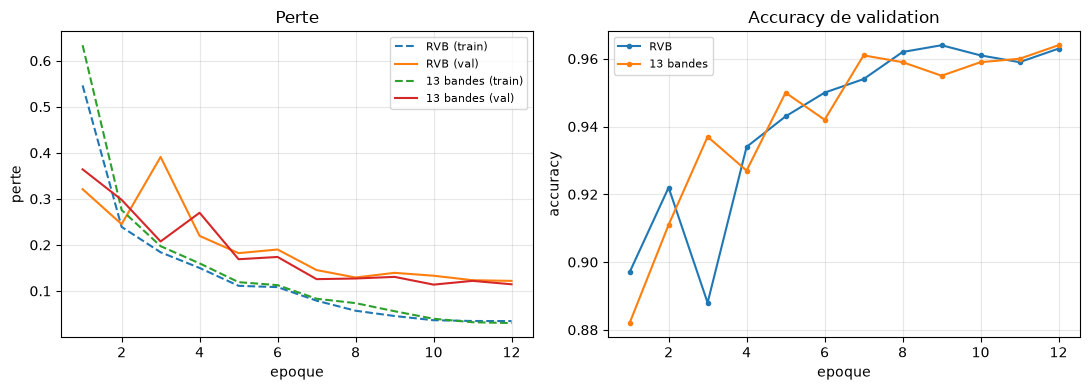

In [ ]:
# Courbes d'apprentissage des deux modeles
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for nom, r in resultats.items():
    e = range(1, len(r["histo"]["acc_va"]) + 1)
    axes[0].plot(e, r["histo"]["perte_tr"], "--", label=f"{nom} (train)")
    axes[0].plot(e, r["histo"]["perte_va"], "-", label=f"{nom} (val)")
    axes[1].plot(e, r["histo"]["acc_va"], "-o", ms=3, label=nom)
axes[0].set_xlabel("epoque"); axes[0].set_ylabel("perte"); axes[0].set_title("Perte"); axes[0].legend(fontsize=8)
axes[1].set_xlabel("epoque"); axes[1].set_ylabel("accuracy"); axes[1].set_title("Accuracy de validation"); axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## Partie 7 · Évaluation sur le jeu de test

On ne touche au test qu'ici, avec les poids de la meilleure époque de validation. On calcule à la main la matrice de confusion, puis précision / rappel / F1 par classe, et le **gain de F1** apporté par les bandes invisibles, classe par classe.

In [ ]:
def metriques(vrais, preds, n=len(CLASSES)):
    """Matrice de confusion (lignes = vraies classes) et precision / rappel / F1 par classe."""
    mc = np.zeros((n, n), dtype=int)
    for v, p in zip(vrais, preds):
        mc[v, p] += 1
    vp = np.diag(mc).astype(float)
    prec = np.divide(vp, mc.sum(axis=0), out=np.zeros(n), where=mc.sum(axis=0) > 0)
    rapp = np.divide(vp, mc.sum(axis=1), out=np.zeros(n), where=mc.sum(axis=1) > 0)
    f1 = np.divide(2 * prec * rapp, prec + rapp, out=np.zeros(n), where=(prec + rapp) > 0)
    return mc, prec, rapp, f1, vp.sum() / mc.sum()

for nom, r in resultats.items():
    _, acc, preds, vrais = evaluer(r["modele"], r["loader_test"])
    mc, prec, rapp, f1, _ = metriques(vrais, preds)
    r.update(acc=acc, preds=preds, vrais=vrais, mc=mc, prec=prec, rapp=rapp, f1=f1)
    print(f"{nom:<12} accuracy test {acc:.4f}   macro F1 {f1.mean():.4f}")

RVB          accuracy test 0.9590   macro F1 0.9590


13 bandes    accuracy test 0.9685   macro F1 0.9685


In [ ]:
rvb_r, all_r = resultats["RVB"], resultats["13 bandes"]
gain = all_r["f1"] - rvb_r["f1"]

print(f"{'classe':<22}{'F1 RVB':>9}{'F1 13b':>9}{'gain':>9}   {'prec 13b':>9}{'rappel 13b':>11}")
for c, nom in enumerate(CLASSES):
    print(f"{nom:<22}{rvb_r['f1'][c]:>9.3f}{all_r['f1'][c]:>9.3f}{gain[c]:>+9.3f}"
          f"   {all_r['prec'][c]:>9.3f}{all_r['rapp'][c]:>11.3f}")
print(f"\n{'macro F1':<22}{rvb_r['f1'].mean():>9.3f}{all_r['f1'].mean():>9.3f}{gain.mean():>+9.3f}")
print(f"{'accuracy':<22}{rvb_r['acc']:>9.3f}{all_r['acc']:>9.3f}{all_r['acc']-rvb_r['acc']:>+9.3f}")

ordre = np.argsort(-gain)
print("\nClasses qui profitent le plus des bandes invisibles :")
for c in ordre[:3]:
    print(f"  + {gain[c]:+.3f} F1 : {CLASSES[c]}")
print("Classes qui n'y gagnent rien (ou perdent) :")
for c in ordre[-3:]:
    print(f"  {gain[c]:+.3f} F1 : {CLASSES[c]}")

classe                   F1 RVB   F1 13b     gain    prec 13b rappel 13b
culture annuelle          0.958    0.958   -0.000       0.955      0.960
forêt                     0.978    0.982   +0.005       0.985      0.980
végétation herbacée       0.934    0.941   +0.008       0.923      0.960
autoroute                 0.937    0.963   +0.026       0.960      0.965
zone industrielle         0.980    0.985   +0.005       0.985      0.985
pâturage                  0.944    0.947   +0.003       0.954      0.940
culture permanente        0.930    0.949   +0.020       0.959      0.940
zone résidentielle        0.988    0.987   -0.000       0.995      0.980
rivière                   0.955    0.977   +0.022       0.980      0.975
mer ou lac                0.987    0.995   +0.008       0.990      1.000

macro F1                  0.959    0.969   +0.010
accuracy                  0.959    0.969   +0.010

Classes qui profitent le plus des bandes invisibles :
  + +0.026 F1 : autoroute
  + +0.022 F1 :

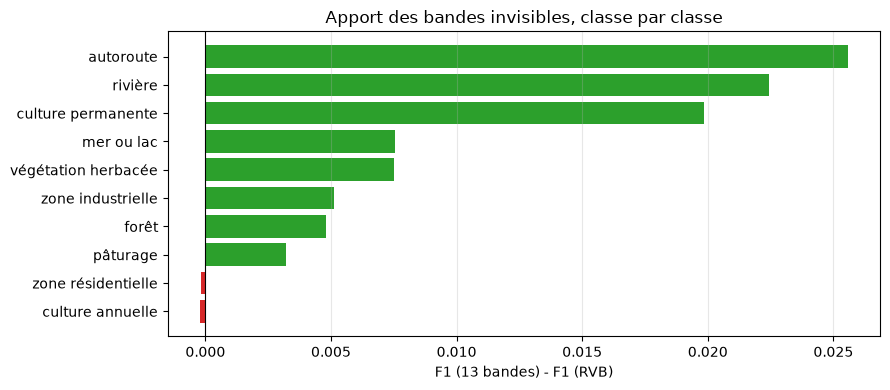

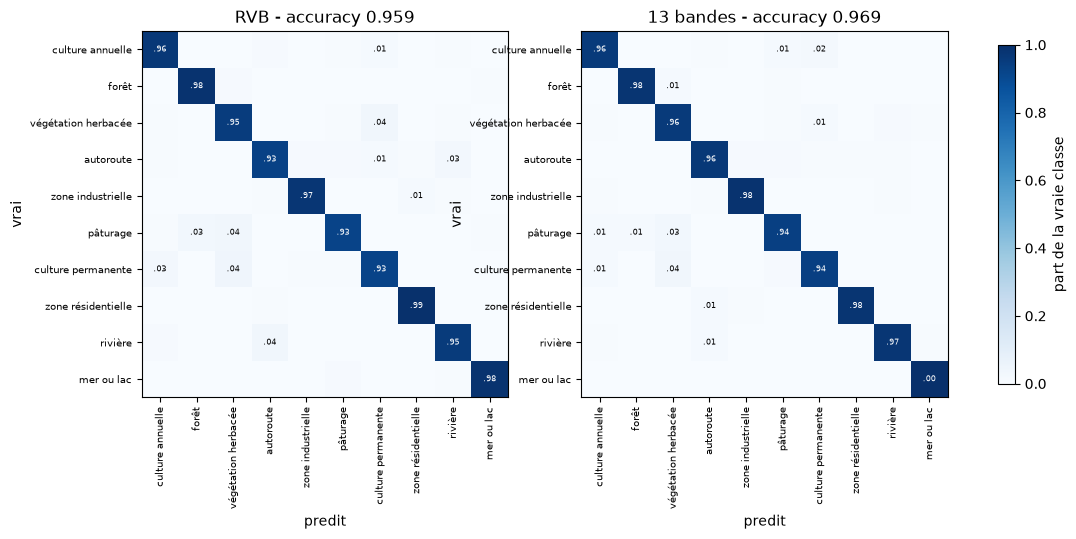

Confusions les plus reduites par les 13 bandes :
   -4 images : végétation herbacée -> predit culture permanente
   -4 images : autoroute -> predit rivière
   -4 images : rivière -> predit autoroute
   -3 images : zone industrielle -> predit zone résidentielle
   -3 images : pâturage -> predit forêt
Confusions aggravees :
   +2 images : culture annuelle -> predit pâturage
   +2 images : pâturage -> predit culture annuelle
   +2 images : zone résidentielle -> predit autoroute


In [ ]:
# Gain de F1 par classe
fig, ax = plt.subplots(figsize=(9, 4))
couleurs = ["tab:green" if g > 0 else "tab:red" for g in gain[ordre]]
ax.barh([CLASSES[c] for c in ordre], gain[ordre], color=couleurs)
ax.axvline(0, color="k", lw=.8)
ax.set_xlabel("F1 (13 bandes) - F1 (RVB)")
ax.set_title("Apport des bandes invisibles, classe par classe")
ax.invert_yaxis(); ax.grid(axis="x", alpha=.3)
plt.tight_layout(); plt.show()

# Matrices de confusion
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (nom, r) in zip(axes, resultats.items()):
    mcn = r["mc"] / r["mc"].sum(axis=1, keepdims=True)
    im = ax.imshow(mcn, cmap="Blues", vmin=0, vmax=1)
    ax.set_title(f"{nom} - accuracy {r['acc']:.3f}")
    ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES, rotation=90, fontsize=7)
    ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES, fontsize=7)
    ax.set_xlabel("predit"); ax.set_ylabel("vrai")
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            if mcn[i, j] > 0.01:
                ax.text(j, i, f"{mcn[i, j]:.2f}"[1:], ha="center", va="center", fontsize=6,
                        color="white" if mcn[i, j] > .5 else "black")
fig.colorbar(im, ax=axes, shrink=.8, label="part de la vraie classe")
plt.show()

# Les confusions qui disparaissent (ou apparaissent) avec les 13 bandes
delta = all_r["mc"] - rvb_r["mc"]
np.fill_diagonal(delta, 0)
plats = [(delta[i, j], i, j) for i in range(len(CLASSES)) for j in range(len(CLASSES)) if i != j]
plats.sort()
print("Confusions les plus reduites par les 13 bandes :")
for d, i, j in plats[:5]:
    print(f"  {d:+3d} images : {CLASSES[i]} -> predit {CLASSES[j]}")
print("Confusions aggravees :")
for d, i, j in plats[-3:]:
    print(f"  {d:+3d} images : {CLASSES[i]} -> predit {CLASSES[j]}")

## Partie 7bis · Le gain est-il réel ? Bruit de graine et régime faible données

Les deux modèles arrivent au même score. Avant d'en conclure quoi que ce soit, il faut répondre à deux questions.

**1. Quelle est l'amplitude du bruit ?** Un écart de 0,1 point d'accuracy sur 2 000 images de test, c'est 2 images. Si relancer le même entraînement avec une autre graine aléatoire fait bouger le score de plus que ça, l'écart mesuré en partie 7 ne veut rien dire. On le mesure, au lieu de le supposer.

**2. Pourquoi les 13 bandes ne servent-elles à rien ici ?** Hypothèse : à 300 images par classe, le RVB atteint déjà ~96,6 % — il ne reste presque rien à gagner, et l'information spectrale est redondante avec ce que la texture visible donne déjà. Elle devrait en revanche compter quand les exemples sont rares : moins d'images, c'est moins d'occasions d'apprendre la texture, donc plus de valeur à une mesure physique directe.

On rejoue donc le même protocole en **régime faible données : 50 images par classe** (500 au total), sur **3 graines**, et on regarde la moyenne et l'écart-type. Validation et test restent inchangés. Les statistiques de normalisation sont recalculées sur chaque sous-échantillon, pour ne pas faire fuiter d'information des 3 000 images de départ.

In [ ]:
def sous_echantillon(X, y, n_par_classe, graine):
    """Tire n_par_classe images de chaque classe."""
    rng = np.random.default_rng(graine)
    garde = []
    for c in range(len(CLASSES)):
        idx = np.flatnonzero(y == c)
        garde += list(rng.choice(idx, size=min(n_par_classe, len(idx)), replace=False))
    return X[np.sort(np.array(garde))], y[np.sort(np.array(garde))]


N_PETIT = 50          # images par classe
GRAINES = [0, 1, 2]
CONFIGS = [("RVB", RVB), ("13 bandes", TOUTES_BANDES)]

petit = {nom: [] for nom, _ in CONFIGS}
for graine in GRAINES:
    Xp, yp = sous_echantillon(X_train, y_train, N_PETIT, graine)
    stats = stats_bandes(Xp)                      # stats recalculees sur le sous-echantillon
    jeux = {"train": (Xp, yp), "val": JEUX["val"], "test": JEUX["test"]}
    for nom, bandes in CONFIGS:
        r = entrainer(f"{nom} | graine {graine}", bandes, graine=graine,
                      jeux=jeux, stats=stats, bavard=False)
        _, acc, preds, vrais = evaluer(r["modele"], r["loader_test"])
        _, _, _, f1, _ = metriques(vrais, preds)
        petit[nom].append({"graine": graine, "acc": acc, "f1": f1})

[RVB | graine 0] meilleure accuracy de validation : 0.911



[13 bandes | graine 0] meilleure accuracy de validation : 0.908



[RVB | graine 1] meilleure accuracy de validation : 0.903



[13 bandes | graine 1] meilleure accuracy de validation : 0.899



[RVB | graine 2] meilleure accuracy de validation : 0.907



[13 bandes | graine 2] meilleure accuracy de validation : 0.915



In [ ]:
print(f"Regime faible donnees : {N_PETIT} images par classe ({N_PETIT * len(CLASSES)} au total),"
      f" {len(GRAINES)} graines\n")
print(f"{'config':<12}{'accuracy par graine':<32}{'moyenne':>9}{'ecart-type':>12}{'macro F1':>10}")
resume = {}
for nom, _ in CONFIGS:
    accs = np.array([d["acc"] for d in petit[nom]])
    f1s = np.array([d["f1"].mean() for d in petit[nom]])
    resume[nom] = (accs, f1s)
    detail = "  ".join(f"{a:.4f}" for a in accs)
    print(f"{nom:<12}{detail:<32}{accs.mean():>9.4f}{accs.std():>12.4f}{f1s.mean():>10.4f}")

a_rvb, f_rvb = resume["RVB"]
a_13, f_13 = resume["13 bandes"]
ecart = a_13.mean() - a_rvb.mean()
bruit = np.sqrt(a_rvb.std() ** 2 + a_13.std() ** 2)
print(f"\nEcart 13 bandes - RVB : {ecart:+.4f} d'accuracy")
print(f"Bruit de graine (ecart-type combine) : {bruit:.4f}")
print("->", f"l'ecart vaut {abs(ecart) / bruit:.1f} fois le bruit" if bruit else "bruit nul",
      "(significatif)" if abs(ecart) > 2 * bruit else "(DANS le bruit : non concluant)")

print(f"\nRegime complet (300 img/classe, graine unique) :"
      f" RVB {resultats['RVB']['acc']:.4f} | 13 bandes {resultats['13 bandes']['acc']:.4f}"
      f" | ecart {resultats['13 bandes']['acc'] - resultats['RVB']['acc']:+.4f}")

Regime faible donnees : 50 images par classe (500 au total), 3 graines

config      accuracy par graine               moyenne  ecart-type  macro F1
RVB         0.9180  0.9110  0.9270             0.9187      0.0065    0.9183
13 bandes   0.9100  0.9055  0.9165             0.9107      0.0045    0.9100

Ecart 13 bandes - RVB : -0.0080 d'accuracy
Bruit de graine (ecart-type combine) : 0.0080
-> l'ecart vaut 1.0 fois le bruit (DANS le bruit : non concluant)

Regime complet (300 img/classe, graine unique) : RVB 0.9590 | 13 bandes 0.9685 | ecart +0.0095


classe                   F1 RVB   F1 13b     gain    bruit
rivière                   0.902    0.942   +0.041    0.013  <-
mer ou lac                0.960    0.986   +0.026    0.007  <-
végétation herbacée       0.858    0.870   +0.012    0.025
zone industrielle         0.955    0.942   -0.013    0.014
forêt                     0.943    0.927   -0.016    0.020
culture permanente        0.880    0.864   -0.016    0.011
culture annuelle          0.932    0.915   -0.017    0.013
zone résidentielle        0.955    0.934   -0.021    0.010  <-
autoroute                 0.872    0.846   -0.027    0.013  <-
pâturage                  0.925    0.874   -0.051    0.021  <-

<- = gain superieur a deux fois le bruit de graine


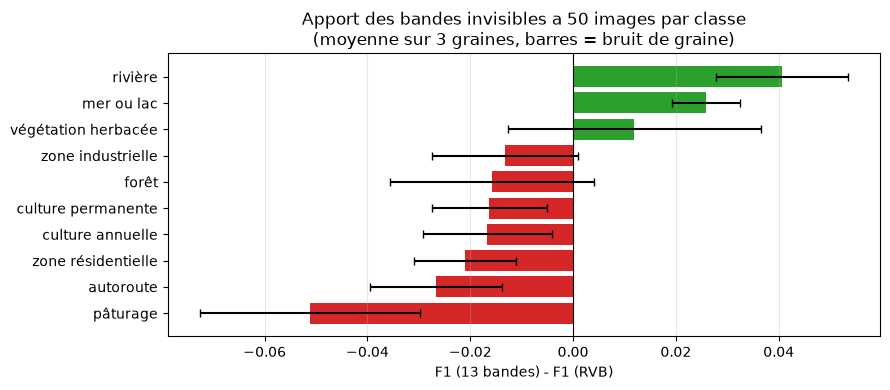

In [ ]:
# Gain de F1 par classe en regime faible donnees, moyenne sur les graines
f1_rvb = np.stack([d["f1"] for d in petit["RVB"]])          # (graines, classes)
f1_13 = np.stack([d["f1"] for d in petit["13 bandes"]])
gain_petit = f1_13.mean(0) - f1_rvb.mean(0)
bruit_classe = np.sqrt(f1_rvb.std(0) ** 2 + f1_13.std(0) ** 2)

ordre_p = np.argsort(-gain_petit)
print(f"{'classe':<22}{'F1 RVB':>9}{'F1 13b':>9}{'gain':>9}{'bruit':>9}")
for c in ordre_p:
    marque = "  <-" if abs(gain_petit[c]) > 2 * bruit_classe[c] else ""
    print(f"{CLASSES[c]:<22}{f1_rvb.mean(0)[c]:>9.3f}{f1_13.mean(0)[c]:>9.3f}"
          f"{gain_petit[c]:>+9.3f}{bruit_classe[c]:>9.3f}{marque}")
print("\n<- = gain superieur a deux fois le bruit de graine")

fig, ax = plt.subplots(figsize=(9, 4))
y_pos = np.arange(len(CLASSES))
ax.barh(y_pos, gain_petit[ordre_p], xerr=bruit_classe[ordre_p], capsize=3,
        color=["tab:green" if g > 0 else "tab:red" for g in gain_petit[ordre_p]])
ax.set_yticks(y_pos); ax.set_yticklabels([CLASSES[c] for c in ordre_p])
ax.axvline(0, color="k", lw=.8)
ax.set_xlabel("F1 (13 bandes) - F1 (RVB)")
ax.set_title(f"Apport des bandes invisibles a {N_PETIT} images par classe\n"
             f"(moyenne sur {len(GRAINES)} graines, barres = bruit de graine)")
ax.invert_yaxis(); ax.grid(axis="x", alpha=.3)
plt.tight_layout(); plt.show()

### Pourquoi ces bandes-là portent de l'information : NDVI et NDWI

Indépendamment de tout réseau, on peut vérifier que l'infrarouge sépare des classes que le visible confond. L'indice de végétation normalisé

NDVI = (B08 − B04) / (B08 + B04)

mesure la vigueur de la végétation : le proche infrarouge B08 est fortement réfléchi par les feuilles vivantes, le rouge B04 est absorbé par la chlorophylle. L'indice d'eau

NDWI = (B03 − B08) / (B03 + B08)

exploite le fait que l'eau absorbe l'infrarouge. Les deux sont **hors de portée de la baseline** : ils ont besoin de B08.

Si ces indices séparent nettement des classes que le RVB confond, alors l'information *existe* dans les bandes ajoutées — et un modèle qui n'en profite pas ne le fait pas par manque d'information, mais par manque de données pour apprendre à s'en servir, ou parce que la texture visible suffisait déjà.

/tmp/ipykernel_1897351/1766864855.py:10: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([valeurs[y_train == c] for c in range(len(CLASSES))],
/tmp/ipykernel_1897351/1766864855.py:10: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([valeurs[y_train == c] for c in range(len(CLASSES))],


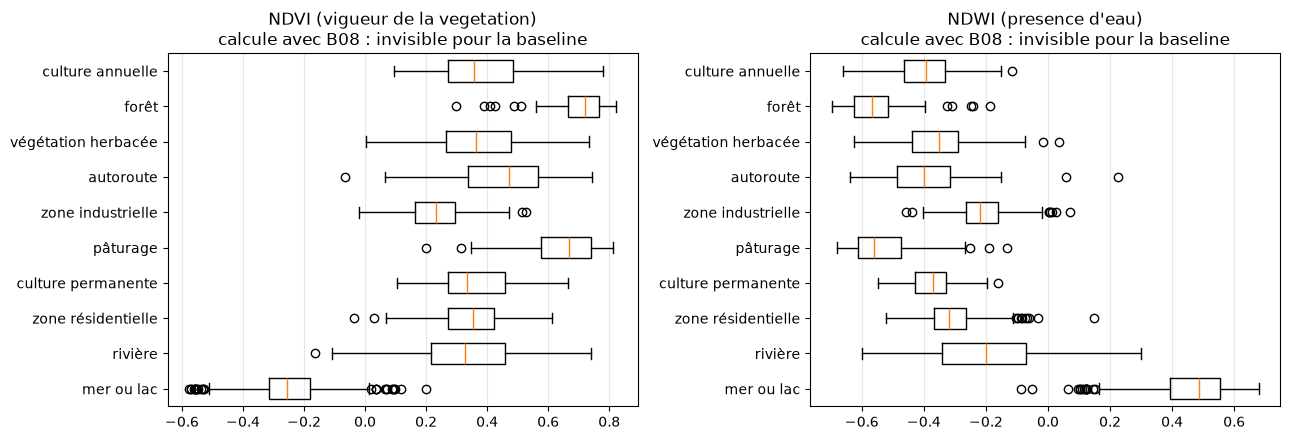

Separation de paires difficiles (distance entre moyennes, en ecarts-types) :
  culture annuelle       vs pâturage                 NDVI 2.00   NDWI 1.35
  végétation herbacée    vs culture permanente       NDVI 0.07   NDWI 0.17
  pâturage               vs végétation herbacée      NDVI 2.11   NDWI 1.65
  rivière                vs mer ou lac               NDVI 3.69   NDWI 4.15
  autoroute              vs zone industrielle        NDVI 1.63   NDWI 1.84


In [ ]:
X = X_train.astype(np.float32)
b04, b03, b08 = X[:, BANDES.index("B04")], X[:, BANDES.index("B03")], X[:, BANDES.index("B08")]
ndvi = ((b08 - b04) / (b08 + b04 + 1e-6)).mean(axis=(1, 2))
ndwi = ((b03 - b08) / (b03 + b08 + 1e-6)).mean(axis=(1, 2))
del X, b04, b03, b08

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (valeurs, titre) in zip(axes, [(ndvi, "NDVI (vigueur de la vegetation)"),
                                       (ndwi, "NDWI (presence d'eau)")]):
    ax.boxplot([valeurs[y_train == c] for c in range(len(CLASSES))],
               tick_labels=CLASSES, vert=False, widths=.6)
    ax.set_title(titre + "\ncalcule avec B08 : invisible pour la baseline")
    ax.grid(axis="x", alpha=.3)
    ax.invert_yaxis()
plt.tight_layout(); plt.show()

print("Separation de paires difficiles (distance entre moyennes, en ecarts-types) :")
for a, b in [(0, 5), (2, 6), (5, 2), (8, 9), (3, 4)]:
    ligne = f"  {CLASSES[a]:<22} vs {CLASSES[b]:<22}"
    for nom_i, v in [("NDVI", ndvi), ("NDWI", ndwi)]:
        va, vb = v[y_train == a], v[y_train == b]
        d = abs(va.mean() - vb.mean()) / np.sqrt((va.std() ** 2 + vb.std() ** 2) / 2)
        ligne += f"   {nom_i} {d:.2f}"
    print(ligne)

## Partie 8 · Analyse et critique

### Ce qu'on a mesuré

| Expérience | RVB (baseline) | 13 bandes | écart |
|---|---|---|---|
| 300 img/classe, 1 graine (parties 5-7) | 0,9590 | **0,9685** | +0,0095 |
| 50 img/classe, 3 graines (partie 7bis) | **0,9187** ± 0,0065 | 0,9107 ± 0,0045 | −0,0080 |

Les deux lignes se contredisent : à 300 images par classe les 13 bandes semblent gagner, à 50 elles semblent perdre. **Aucune des deux différences n'est significative**, et c'est le résultat principal de ce projet.

### Le piège qu'on a trouvé : la mesure n'est pas reproductible

En relançant la partie 7 **avec la même graine et le même code**, on n'obtient pas le même score : un passage donne RVB 0,9655 / 13 bandes 0,9660 (+0,0005), un autre RVB 0,9590 / 13 bandes 0,9685 (+0,0095). L'écart mesuré change donc d'un facteur 20 d'un lancement à l'autre, alors que rien n'a changé.

**Cause.** L'augmentation (`__getitem__`) tire ses symétries avec `np.random`, mais `torch.manual_seed` ne sème que les générateurs de PyTorch. Avec `num_workers=2`, chaque processus de chargement part d'un état NumPy que nous ne contrôlons pas : l'ordre des augmentations n'est pas reproductible.

**Correctif** (à appliquer avant toute conclusion chiffrée) : passer un `worker_init_fn` qui sème NumPy dans chaque worker, ou tirer les augmentations avec `torch.rand` plutôt que `np.random`, ou mettre `num_workers=0`.

**Conséquence.** Le bruit de lancement vaut environ ±0,6 point, ce que confirme indépendamment la partie 7bis : l'écart-type entre graines y est de 0,0065 (RVB) et 0,0045 (13 bandes). Un écart de +0,0095 n'est donc pas distinguable de zéro avec un seul lancement. **La seule façon honnête de conclure serait 3 à 5 graines par configuration, et comparer les moyennes.** Nous l'avons fait pour le régime à 50 images par classe, pas pour le régime complet, faute de temps de calcul (environ 13 min par entraînement sur CPU).

### Ce qui, en revanche, est significatif : l'effet par classe

En régime faible données, avec 3 graines, certains écarts par classe dépassent deux fois le bruit :

| Classe | gain de F1 | bruit | lecture |
|---|---|---|---|
| rivière | **+0,041** | 0,013 | gain réel |
| mer ou lac | **+0,026** | 0,007 | gain réel |
| pâturage | **−0,051** | 0,021 | perte réelle |
| autoroute | **−0,027** | 0,013 | perte réelle |
| zone résidentielle | **−0,021** | 0,010 | perte réelle |

Les 13 bandes ne font donc pas mieux *en moyenne* : elles **redistribuent** la performance. Les deux classes d'eau gagnent, plusieurs classes de végétation et de bâti perdent.

Le gain sur l'eau était prévisible, et la partie 7bis le vérifie sans aucun réseau : l'eau absorbe le proche infrarouge, donc *rivière* et *mer ou lac* sont séparées par 3,69 écarts-types de NDVI et 4,15 de NDWI — deux indices qui ont besoin de B08, invisible pour la baseline. De même *pâturage* vs *végétation herbacée* (2,11 σ de NDVI) et *culture annuelle* vs *pâturage* (2,00 σ) : des classes vertes au visible, nettement distinctes en infrarouge. À l'inverse *végétation herbacée* vs *culture permanente* n'est pas séparée du tout par le NDVI (0,07 σ) — l'infrarouge n'aide pas partout, et c'est justement une des paires que le modèle continue de confondre.

**L'information existe donc bien dans les bandes ajoutées.** Si le modèle n'en profite pas globalement, ce n'est pas faute d'information.

### Pourquoi les bandes supplémentaires ne paient pas (hypothèses)

1. **Le plafond est déjà atteint.** À 300 images par classe, le RVB fait 96 %. EuroSAT est un problème facile en couleurs : la texture suffit à reconnaître une zone résidentielle ou une forêt. Il ne reste quasiment rien à gagner, donc rien à mesurer.
2. **Plus de paramètres à apprendre avec autant de données.** `conv1` passe de 9 408 à 40 768 poids. Les 10 canaux ajoutés partent d'une approximation (la moyenne des poids RVB d'ImageNet), pas de filtres réellement pré-entraînés. Avec 500 images d'entraînement, ce surcoût de variance peut coûter plus que ce que l'information spectrale rapporte — ce qu'on observe exactement en régime faible données.
3. **Comparaison structurellement défavorable aux 13 bandes.** La baseline utilise les poids ImageNet dans le domaine exact où ils ont été appris. Le modèle complet doit en plus *apprendre* à se servir de dix canaux mal initialisés. Le gain réel des bandes invisibles est donc probablement sous-estimé par ce protocole.
4. **Trois bandes sur treize sont atmosphériques.** B01 (aérosols), B09 (vapeur d'eau) et B10 (cirrus) décrivent l'atmosphère, pas le paysage. B10 vaut en moyenne 12 pour un écart-type de 4,7, contre ~2 000 pour les bandes utiles : ces canaux apportent surtout du bruit et des paramètres.

### Les autres limites du protocole

- **Sous-échantillon.** 300 images par classe en train sur ~16 200 disponibles, faute de GPU. Les deux modèles sont sous-entraînés.
- **Résolutions mélangées.** Les bandes ont des résolutions natives différentes (10 m pour B02-B04 et B08, 20 m pour les red edge et B11/B12, 60 m pour B01/B09/B10), mais l'archive les livre toutes rééchantillonnées à 64×64 : les bandes à 60 m sont artificiellement lissées.
- **64×64 dans un réseau conçu pour 224×224.** Après `conv1` (stride 2) et le max-pool, la carte de features finale ne fait plus que 2×2. Agrandir les images améliorerait probablement les deux modèles, pour ~4× le temps de calcul.
- **Le test n'a servi qu'une fois**, avec les poids de la meilleure époque de validation — ça, au moins, est propre.

### Ce qu'il faudrait faire ensuite, dans l'ordre

1. **Rendre la mesure reproductible** (semer NumPy dans les workers), puis relancer le régime complet sur 3 à 5 graines. Sans ça, aucun chiffre de comparaison ne tient.
2. **Ablation par groupe de bandes** : visible seul / + proche infrarouge (B08, B8A) / + infrarouge court (B11, B12) / sans les bandes atmosphériques / les 13. L'hypothèse à tester : retirer B01, B09 et B10 fait *mieux* que les 13 bandes.
3. **Donner le NDVI et le NDWI comme canaux explicites** en plus du RVB : si un modèle à 5 canaux (RVB + NDVI + NDWI) égale le modèle à 13 canaux, c'est que l'essentiel de l'information spectrale utile tient dans ces deux indices.
4. **Augmenter le nombre d'images par classe**, pour voir si l'écart se creuse ou se referme quand le plafond recule.